In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
import xgboost 
import pickle

In [2]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [3]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [4]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [5]:
# Set of variables kept at 20 right now!

In [6]:
# Set of 20 variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [7]:
len(feature_cols)

20

In [8]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [9]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [10]:
len(df_sig_85), len(df_bkg_85), len(df_sig_70), len(df_bkg_70)

# WP 70: 323900, 3959 


(358887, 5855, 323900, 3959)

In [11]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


In [12]:
data = [
    ["tty prod NLO", "Prompts", len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70)],
    ["tty prod NLO", "Fakes", len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70)],
    ["tty dec LO", "Prompts", len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70)],
    ["tty dec LO", "Fakes", len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70)],
    ["Wyy", "Prompts", len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70)],
    ["Wyy", "Fakes", len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70)],
    ["Zyy", "Prompts", len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70)],
    ["Zyy", "Fakes", len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70)],
]

# Print the data in a tabular format
print(f"{'Process':<15} {'Type':<10} {'85 Cut':<10} {'70 Cut':<10}")
print("-" * 45)
for row in data:
    print(f"{row[0]:<15} {row[1]:<10} {row[2]:<10} {row[3]:<10}")

print("-" * 45)

print(f"{'Total:':<25} {len(df_bkg_85):<10} {len(df_bkg_70):<10}")

Process         Type       85 Cut     70 Cut    
---------------------------------------------
tty prod NLO    Prompts    222        203       
tty prod NLO    Fakes      1928       1748      
tty dec LO      Prompts    141        126       
tty dec LO      Fakes      1036       942       
Wyy             Prompts    368        130       
Wyy             Fakes      0          0         
Zyy             Prompts    2073       774       
Zyy             Fakes      87         36        
---------------------------------------------
Total:                    5855       3959      


In [13]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [14]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [15]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007276
std        0.015533
min       -0.024470
25%       -0.009675
50%        0.014474
75%        0.019296
max        0.025153
Name: weight, dtype: float64


In [16]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

2804

In [17]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [ ]:
# helper reference df_sig['ph_conversion_type[:,0]'], df_bkg['ph_conversion_type[:,0]']

In [ ]:
# helper reference using np.where: BEWARE -> remove either this or ABOVE
#df_bkg['ph_conversion_type[:,0]'] = np.where(df_bkg['ph_conversion_type[:,0]'] > 0, 1,0)

#df_sig['ph_conversion_type[:,0]'] = np.where(df_sig['ph_conversion_type[:,0]'] > 0, 1,0)


In [22]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]']


(entry
 0         0
 1         3
 2         0
 3         3
 4         0
          ..
 361992    0
 361993    0
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,0], Length: 358887, dtype: int32,
 entry
 9       3
 10      0
 39      0
 42      1
 43      3
        ..
 2415    2
 2416    0
 2417    1
 2418    0
 2419    0
 Name: ph_conversion_type[:,0], Length: 2804, dtype: int32,
 entry
 0       3
 1       0
 2       0
 3       0
 4       2
        ..
 1888    0
 1896    3
 1910    3
 1923    0
 1945    0
 Name: ph_conversion_type[:,0], Length: 3051, dtype: int32)

In [23]:
df_sig_85['ph_conversion_type[:,1]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]']

(entry
 0         0
 1         0
 2         0
 3         0
 4         2
          ..
 361992    0
 361993    2
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,1], Length: 358887, dtype: int32,
 entry
 9       0
 10      3
 39      2
 42      3
 43      3
        ..
 2415    0
 2416    0
 2417    2
 2418    0
 2419    2
 Name: ph_conversion_type[:,1], Length: 2804, dtype: int32,
 entry
 0       3
 1       0
 2       4
 3       3
 4       0
        ..
 1888    0
 1896    3
 1910    0
 1923    3
 1945    2
 Name: ph_conversion_type[:,1], Length: 3051, dtype: int32)

In [26]:
df_sig_85['ph_conversion_type[:,0]'] = np.where(df_sig_85['ph_conversion_type[:,0]'] > 0, 1,0)

In [27]:
df_sig_85['ph_conversion_type[:,1]'] = np.where(df_sig_85['ph_conversion_type[:,1]'] > 0, 1,0)

In [24]:

df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'] = np.where(df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'] > 0, 1,0)
df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]'] = np.where(df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]'] > 0, 1,0)

In [25]:
df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'] = np.where(df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'] > 0, 1,0)
df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]'] = np.where(df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]'] > 0, 1,0)

In [28]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]']


(entry
 0         0
 1         1
 2         0
 3         1
 4         0
          ..
 361992    0
 361993    0
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,0], Length: 358887, dtype: int64,
 entry
 9       1
 10      0
 39      0
 42      1
 43      1
        ..
 2415    1
 2416    0
 2417    1
 2418    0
 2419    0
 Name: ph_conversion_type[:,0], Length: 2804, dtype: int64,
 entry
 0       1
 1       0
 2       0
 3       0
 4       1
        ..
 1888    0
 1896    1
 1910    1
 1923    0
 1945    0
 Name: ph_conversion_type[:,0], Length: 3051, dtype: int64)

In [29]:
df_sig_85['ph_conversion_type[:,1]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]']

(entry
 0         0
 1         0
 2         0
 3         0
 4         1
          ..
 361992    0
 361993    1
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,1], Length: 358887, dtype: int64,
 entry
 9       0
 10      1
 39      1
 42      1
 43      1
        ..
 2415    0
 2416    0
 2417    1
 2418    0
 2419    1
 Name: ph_conversion_type[:,1], Length: 2804, dtype: int64,
 entry
 0       1
 1       0
 2       1
 3       1
 4       0
        ..
 1888    0
 1896    1
 1910    0
 1923    1
 1945    1
 Name: ph_conversion_type[:,1], Length: 3051, dtype: int64)

# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics) starting with 33 estimators

In [30]:
n_estimators = 33

In [44]:
df_sig_85_reweighted = df_sig_85

In [43]:

nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

    
    
        
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    

    
    print("\n\n\nSignal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ",len(X_bkg_train_prompts), len(w_bkg_train_prompts), len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_prompts), len(w_bkg_test_prompts), len(X_bkg_test_fakes), len(w_bkg_test_fakes))
    print(f"Fold {fold}:")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")



    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
    
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
 
    with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_3Class_Model8_33Est_20VarsConvBinned_Fold{fold}_Thesis.pkl', 'wb') as f:
        pickle.dump(model, f)
                       
    




Signal train test(events,weights):  269250 269250 89637 89637
Background train test(events,weights):  2100 2100 2303 2303 704 704 748 748
Fold 0:
Training: Class 0: 269250, Class 1: 2100, Class 2: 2303

Testing: Class 0: 89637, Class 1: 704, Class 2: 748
Train scores 0: [0.6797485465745688]
Test scores 0:  [0.615452470724906]
99



Signal train test(events,weights):  269313 269313 89574 89574
Background train test(events,weights):  2106 2106 2321 2321 698 698 730 730
Fold 1:
Training: Class 0: 269313, Class 1: 2106, Class 2: 2321

Testing: Class 0: 89574, Class 1: 698, Class 2: 730
Train scores 1: [0.6797485465745688, 0.675670042759078]
Test scores 1:  [0.615452470724906, 0.6194728632520519]
99



Signal train test(events,weights):  269051 269051 89836 89836
Background train test(events,weights):  2127 2127 2268 2268 677 677 783 783
Fold 2:
Training: Class 0: 269051, Class 1: 2127, Class 2: 2268

Testing: Class 0: 89836, Class 1: 677, Class 2: 783
Train scores 2: [0.6797485465745688

In [33]:
# Getting values for loss - Works

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)

n_estimators = 33


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
        w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]

        X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
        w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]

        X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]

        X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]


        y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
        X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
        w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
        y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
        X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
        w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

99


In [36]:
mplhep.style.use('ATLAS')

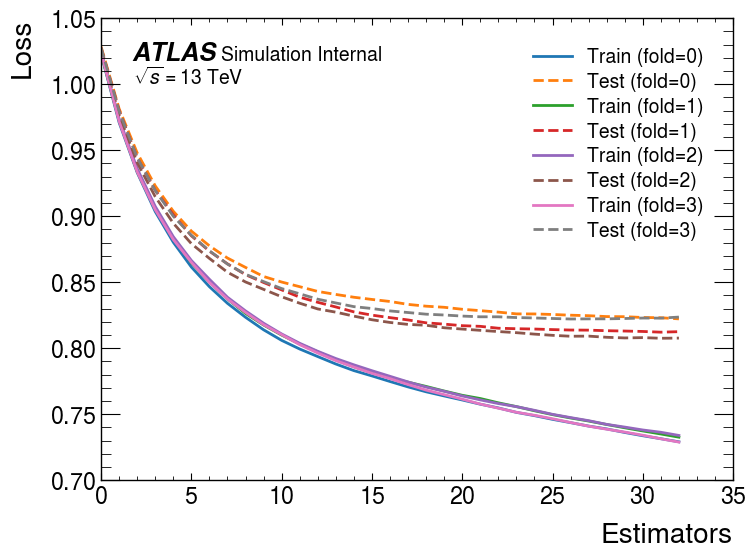

In [37]:

nfolds = 4
n_estimators = 33
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [38]:
X_sig = df_sig_85[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompt_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes_85_reweighted[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scores:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.34341452 0.6349607 0.696378
Length sig:  358887
Length bkg:  2804
Length bkg:  3051


[0.42  0.203 0.377]


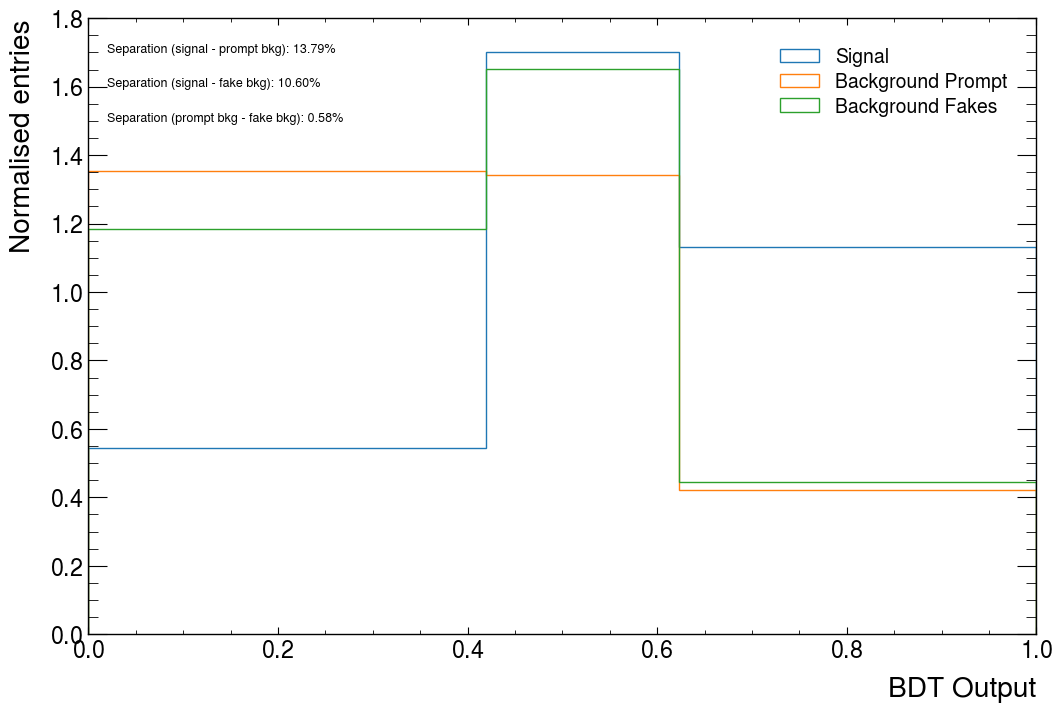

In [39]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.42, 0.623, 1]   #### CHANGE THE BINNING

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompt_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.70, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.60, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.50, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

#plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()


In [40]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompt_85_reweighted,df_bkg_fakes_85_reweighted])

df_bkg_weight = np.concatenate([df_bkg_prompt_85_reweighted['weight'],df_bkg_fakes_85_reweighted['weight']])

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

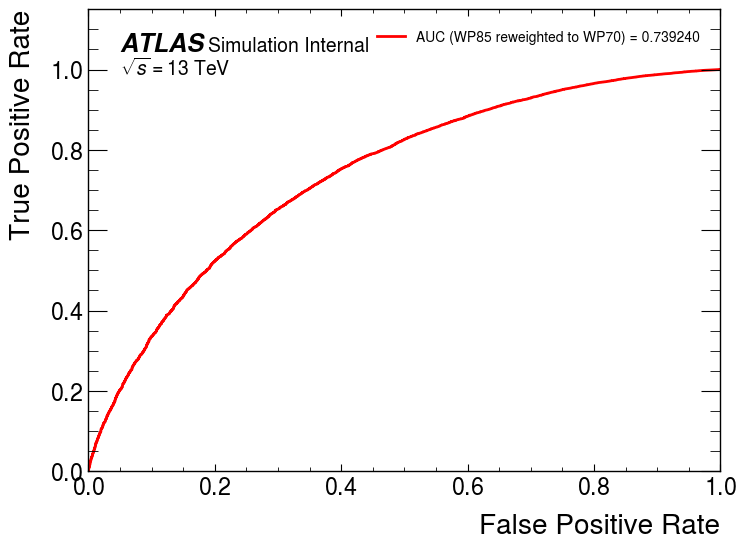

In [41]:
# Aggregate AUC 

scores_85_reweighted_3class = np.concatenate([results_sig, results_bkg])
y_85_reweighted_3class = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr_85_reweighted_3class, tpr_85_reweighted_3class, thresholds_85_reweighted_3class = metrics.roc_curve(y_85_reweighted_3class, scores_85_reweighted_3class, pos_label=1)
AUC_85_reweighted_3class = metrics.roc_auc_score(y_85_reweighted_3class, scores_85_reweighted_3class)

plt.plot(fpr_85_reweighted_3class,tpr_85_reweighted_3class,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted_3class:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
#np.savez('roc_data_85_reweighted_perprocess_3class.npz', fpr=fpr_85_reweighted_3class, tpr=tpr_85_reweighted_3class, thresholds=thresholds_85_reweighted_3class, auc=AUC_85_reweighted_3class)
#print("Data saved to 'roc_data_85_reweighted_perprocess_3class.npz'")

# ##############################

# ##############################

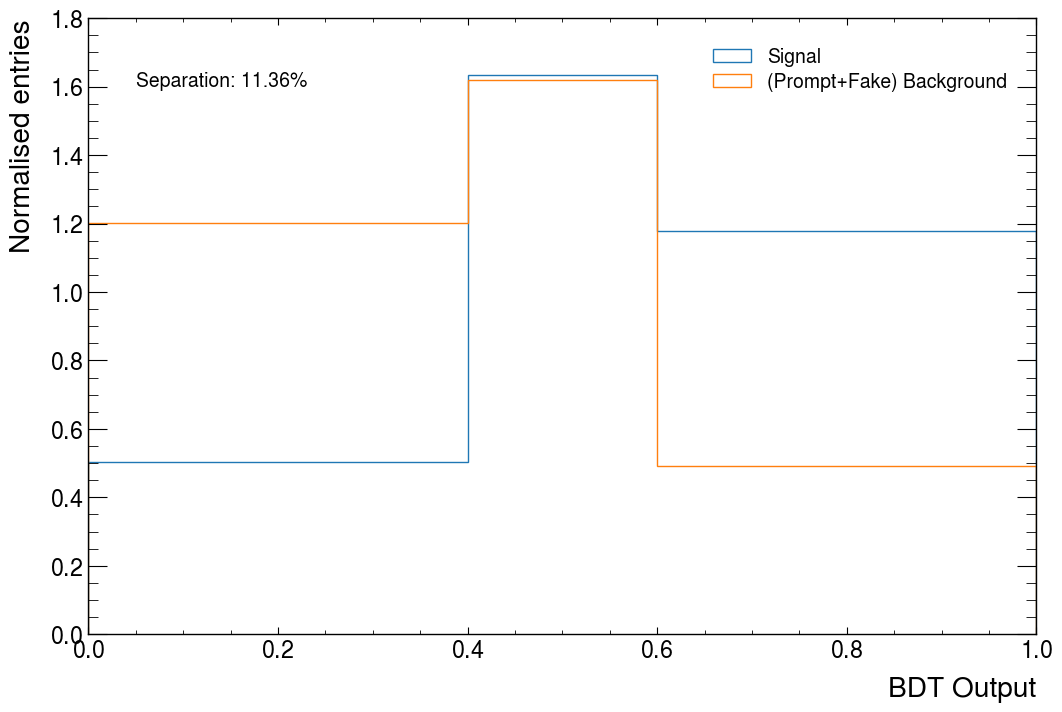

In [42]:
plt.figure(figsize=(12, 8))


# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='(Prompt+Fake) Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins_3class_converged.pdf')
plt.legend()


In [ ]:
# 19 variables

In [45]:
# Set of 19 variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                #'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 2 times.


In [46]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [47]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)

In [48]:
len(df_sig_85), len(df_bkg_85), len(df_sig_70), len(df_bkg_70)

# WP 70: 323900, 3959 


df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)

In [49]:
data = [
    ["tty prod NLO", "Prompts", len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70)],
    ["tty prod NLO", "Fakes", len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70)],
    ["tty dec LO", "Prompts", len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70)],
    ["tty dec LO", "Fakes", len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70)],
    ["Wyy", "Prompts", len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70)],
    ["Wyy", "Fakes", len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70)],
    ["Zyy", "Prompts", len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70)],
    ["Zyy", "Fakes", len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70)],
]

In [50]:
# Print the data in a tabular format
print(f"{'Process':<15} {'Type':<10} {'85 Cut':<10} {'70 Cut':<10}")
print("-" * 45)
for row in data:
    print(f"{row[0]:<15} {row[1]:<10} {row[2]:<10} {row[3]:<10}")

print("-" * 45)

print(f"{'Total:':<25} {len(df_bkg_85):<10} {len(df_bkg_70):<10}")

Process         Type       85 Cut     70 Cut    
---------------------------------------------
tty prod NLO    Prompts    222        203       
tty prod NLO    Fakes      1928       1748      
tty dec LO      Prompts    141        126       
tty dec LO      Fakes      1036       942       
Wyy             Prompts    368        130       
Wyy             Fakes      0          0         
Zyy             Prompts    2073       774       
Zyy             Fakes      87         36        
---------------------------------------------
Total:                    5855       3959      


In [51]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())

count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [52]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)

In [53]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())

count    222.000000
mean       0.007276
std        0.015533
min       -0.024470
25%       -0.009675
50%        0.014474
75%        0.019296
max        0.025153
Name: weight, dtype: float64


In [54]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [ ]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]']

In [ ]:
#df_sig_85['ph_conversion_type[:,1]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]']

In [ ]:
df_sig_85['ph_conversion_type[:,0]'] = np.where(df_sig_85['ph_conversion_type[:,0]'] > 0, 1,0)

#df_sig_85['ph_conversion_type[:,1]'] = np.where(df_sig_85['ph_conversion_type[:,1]'] > 0, 1,0)

In [ ]:
df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'] = np.where(df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'] > 0, 1,0)
df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]'] = np.where(df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]'] > 0, 1,0)

#df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'] = np.where(df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'] > 0, 1,0)
#df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]'] = np.where(df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]'] > 0, 1,0)

In [56]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,0]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,0]']


#df_sig_85['ph_conversion_type[:,1]'], df_bkg_prompt_85_reweighted['ph_conversion_type[:,1]'], df_bkg_fakes_85_reweighted['ph_conversion_type[:,1]']

(entry
 0         0
 1         1
 2         0
 3         1
 4         0
          ..
 361992    0
 361993    0
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,0], Length: 358887, dtype: int64,
 entry
 9       1
 10      0
 39      0
 42      1
 43      1
        ..
 2415    1
 2416    0
 2417    1
 2418    0
 2419    0
 Name: ph_conversion_type[:,0], Length: 2804, dtype: int64,
 entry
 0       1
 1       0
 2       0
 3       0
 4       1
        ..
 1888    0
 1896    1
 1910    1
 1923    0
 1945    0
 Name: ph_conversion_type[:,0], Length: 3051, dtype: int64)

In [65]:
# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics) starting with 33 estimators

n_estimators = 33

df_sig_85_reweighted = df_sig_85


nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

    
    
        
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    
    print("\n\n\nSignal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ",len(X_bkg_train_prompts), len(w_bkg_train_prompts), len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_prompts), len(w_bkg_test_prompts), len(X_bkg_test_fakes), len(w_bkg_test_fakes))
    print(f"Fold {fold}:")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")



    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
    
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
 
    with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_3Class_Model8_33Est_19VarsConvBinned_Fold{fold}_Thesis.pkl', 'wb') as f:
        pickle.dump(model, f)
                       
 




Signal train test(events,weights):  269250 269250 89637 89637
Background train test(events,weights):  2100 2100 2303 2303 704 704 748 748
Fold 0:
Training: Class 0: 269250, Class 1: 2100, Class 2: 2303

Testing: Class 0: 89637, Class 1: 704, Class 2: 748
Train scores 0: [0.6697977467475816]
Test scores 0:  [0.6039622123390531]
99



Signal train test(events,weights):  269313 269313 89574 89574
Background train test(events,weights):  2106 2106 2321 2321 698 698 730 730
Fold 1:
Training: Class 0: 269313, Class 1: 2106, Class 2: 2321

Testing: Class 0: 89574, Class 1: 698, Class 2: 730
Train scores 1: [0.6697977467475816, 0.6659242014032778]
Test scores 1:  [0.6039622123390531, 0.605204118338482]
99



Signal train test(events,weights):  269051 269051 89836 89836
Background train test(events,weights):  2127 2127 2268 2268 677 677 783 783
Fold 2:
Training: Class 0: 269051, Class 1: 2127, Class 2: 2268

Testing: Class 0: 89836, Class 1: 677, Class 2: 783
Train scores 2: [0.66979774674758

In [58]:
   

# Getting values for loss - Works

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)

n_estimators = 33


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
        w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]

        X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
        w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]

        X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]

        X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]


        y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
        X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
        w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
        y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
        X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
        w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

99


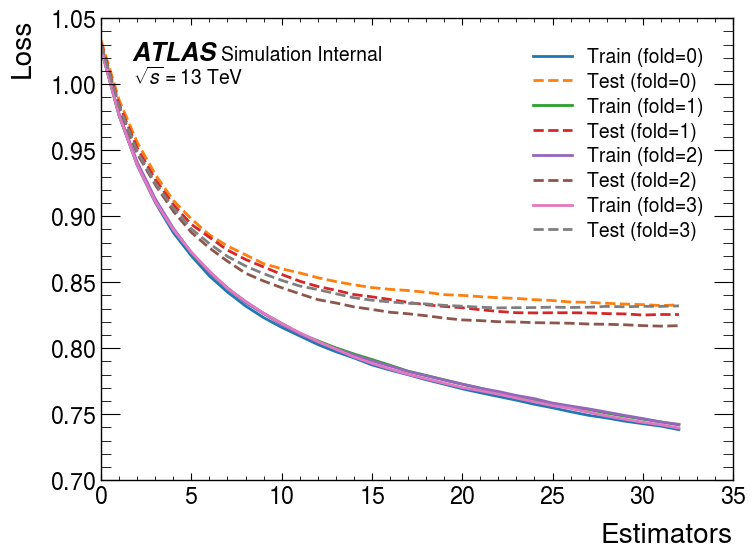

In [59]:
mplhep.style.use('ATLAS')


nfolds = 4
n_estimators = 33
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [60]:
X_sig = df_sig_85[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompt_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes_85_reweighted[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scores:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.4055735 0.6173912 0.686561
Length sig:  358887
Length bkg:  2804
Length bkg:  3051


[0.4 0.2 0.4]


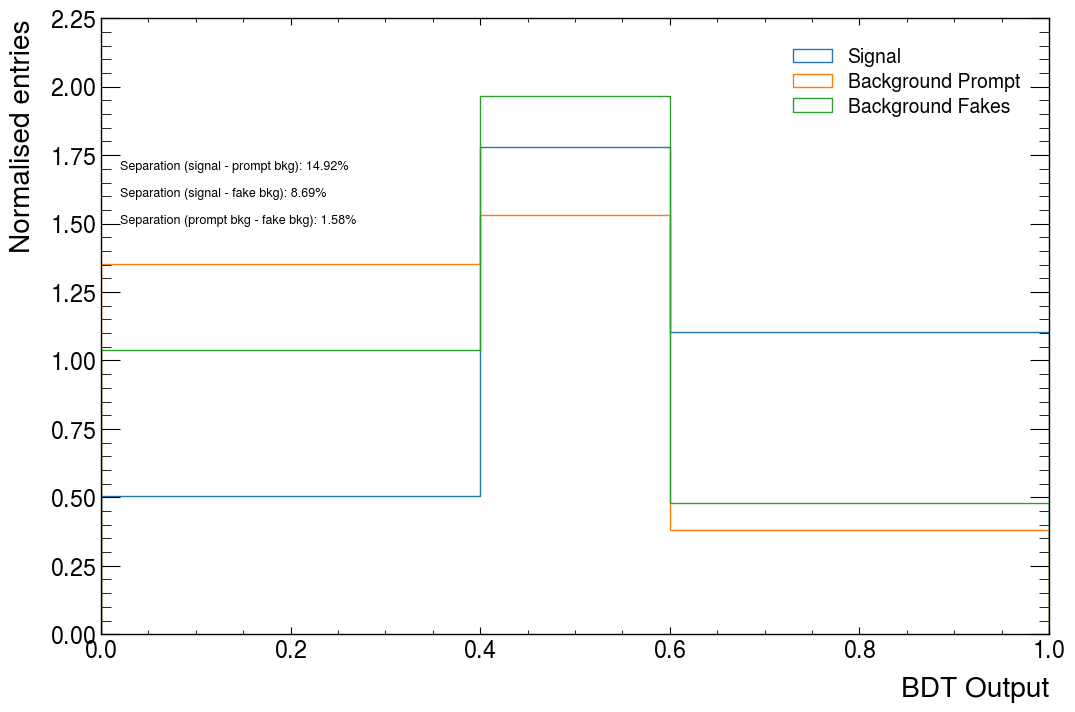

In [61]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompt_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.70, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.60, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.50, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

#plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()

In [62]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompt_85_reweighted,df_bkg_fakes_85_reweighted])

df_bkg_weight = np.concatenate([df_bkg_prompt_85_reweighted['weight'],df_bkg_fakes_85_reweighted['weight']])

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

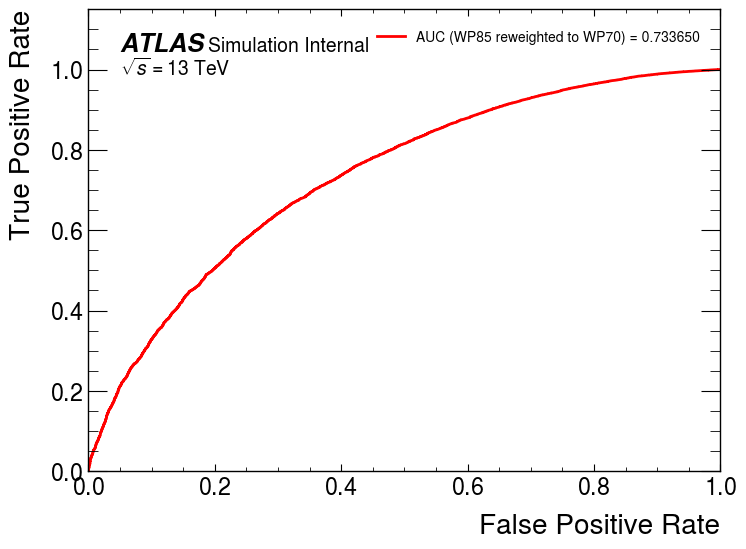

In [63]:
# Aggregate AUC 

scores_85_reweighted_3class = np.concatenate([results_sig, results_bkg])
y_85_reweighted_3class = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr_85_reweighted_3class, tpr_85_reweighted_3class, thresholds_85_reweighted_3class = metrics.roc_curve(y_85_reweighted_3class, scores_85_reweighted_3class, pos_label=1)
AUC_85_reweighted_3class = metrics.roc_auc_score(y_85_reweighted_3class, scores_85_reweighted_3class)

plt.plot(fpr_85_reweighted_3class,tpr_85_reweighted_3class,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted_3class:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
#np.savez('roc_data_85_reweighted_perprocess_3class.npz', fpr=fpr_85_reweighted_3class, tpr=tpr_85_reweighted_3class, thresholds=thresholds_85_reweighted_3class, auc=AUC_85_reweighted_3class)
#print("Data saved to 'roc_data_85_reweighted_perprocess_3class.npz'")

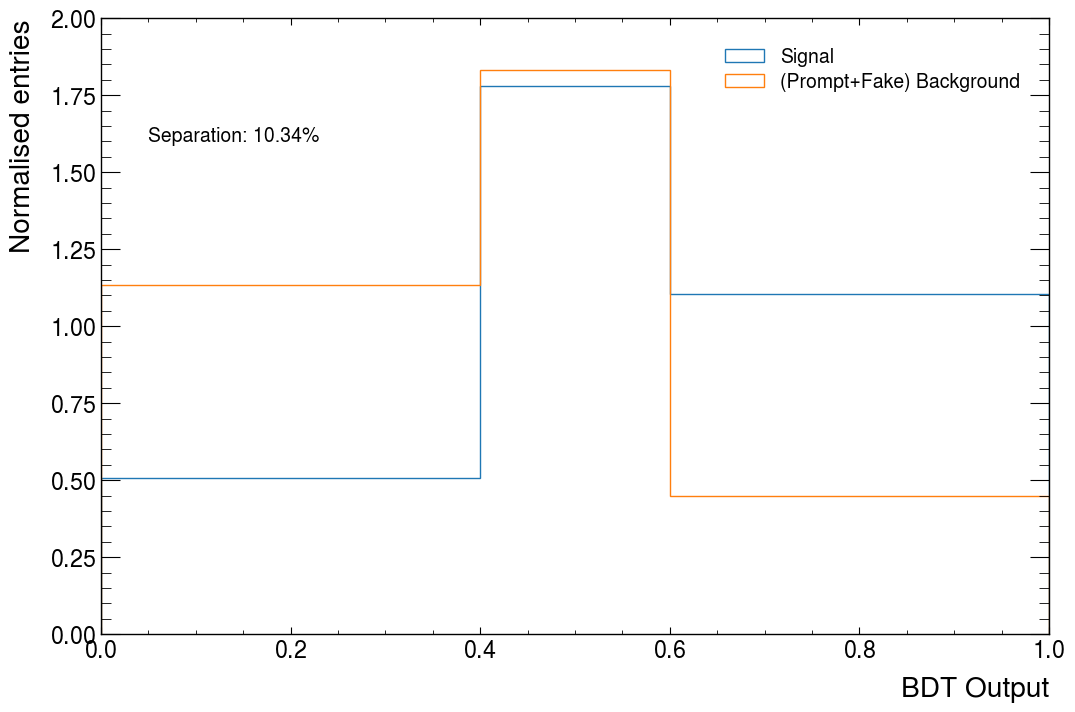

In [64]:
# ##############################

# ##############################

plt.figure(figsize=(12, 8))


# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='(Prompt+Fake) Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins_3class_converged.pdf')
plt.legend()

# NOT CHECKED YET!!!

In [31]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

[0.    0.42  0.623 1.   ]
-----------------------------------------------
0.5303835381742171 1.6422745793297435
0.523303409030995 1.6997449646294043
4 3 3
Signal train histogram: [0.53038354 1.64227458 1.17734002]
Signal test histogram: [0.52330341 1.69974496 1.15428207]
Background train histogram: [1.48161904 1.22105077 0.34442094]
Background test histogram: [1.48890784 1.22982912 0.33157399]
-----------------------------------------------

Signal train errors: [0.03254836 0.03968342 0.04562188]
Signal test errors: [0.01868595 0.02328791 0.02609676]
Background train errors: [1.2402264  0.7089907  0.46678334]
Background test errors: [0.93608147 0.35351133 0.29389158]
-----------------------------------------------

Sig ratio:  [1.01352968 0.96618882 1.01997601]
Bkg ratio:  [0.9951046  0.99286214 1.03874535]

Sig Ratio uncertainties per bin:  [0.07196074 0.02683844 0.04575943]
Clipped errors: [0.07196074 0.02683844 0.04575943]
Clipped errors: [1.04175747 0.64327098 1.68211911]
[0.42  0.

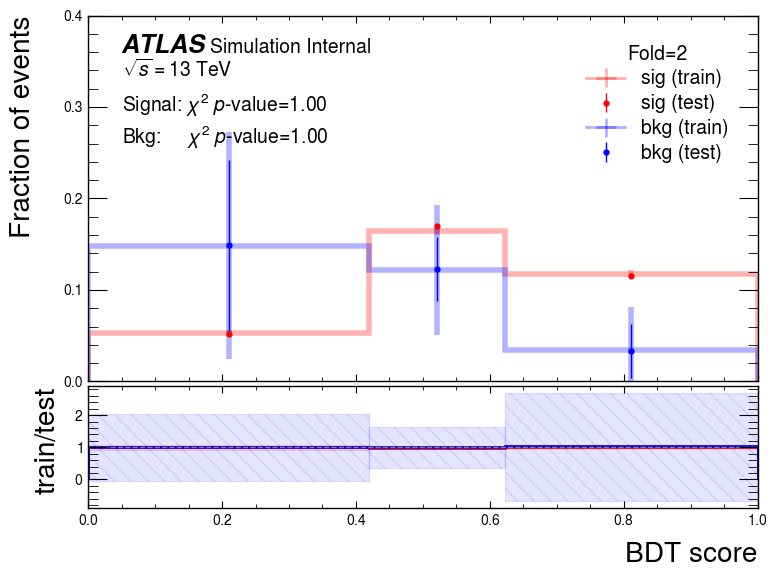

In [44]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.623, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.420, 0.623, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(-0.9,2.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedBins.png')

[0.    0.383 0.598 1.   ]
-----------------------------------------------
0.46441681956100245 1.5356168593455228
0.4560171588555321 1.5870285744140096
4 3 3
Signal train histogram: [0.46441682 1.53561686 1.22380783]
Signal test histogram: [0.45601716 1.58702857 1.20431414]
Background train histogram: [1.41781066 1.38137967 0.3979649 ]
Background test histogram: [1.49480071 1.30527932 0.36531411]
-----------------------------------------------

Signal train errors: [0.02909684 0.03951022 0.04804   ]
Signal test errors: [0.01667857 0.02316352 0.02752833]
Background train errors: [1.1414908 0.8187923 0.534129 ]
Background test errors: [0.9243734  0.35364947 0.32872018]
-----------------------------------------------

Sig ratio:  [1.01841962 0.96760505 1.01618655]
Bkg ratio:  [0.94849477 1.05830196 1.08937728]

Sig Ratio uncertainties per bin:  [0.07388293 0.0286225  0.04616005]
Clipped errors: [0.07388293 0.0286225  0.04616005]
Clipped errors: [0.96290121 0.68971921 1.76030072]
[0.383 0.2

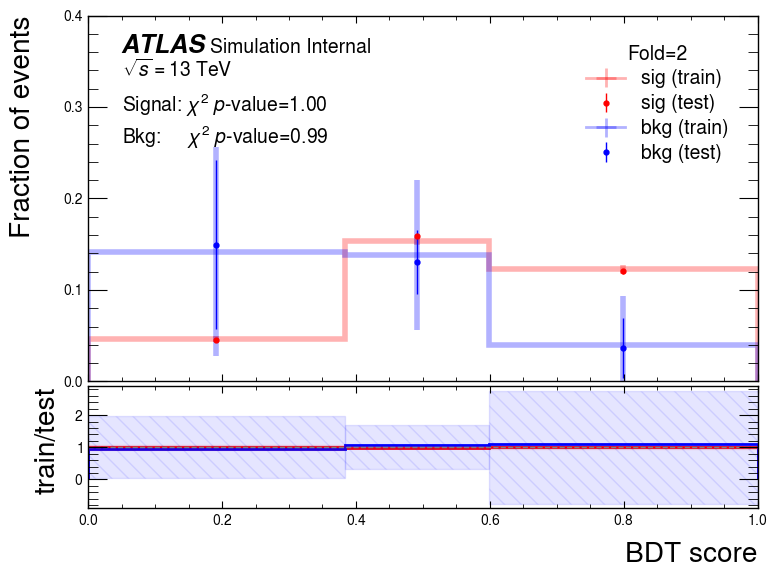

In [52]:
## !!!! KS test with fitted bins used in Analysis

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.383, 0.598, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

#custom_bins = np.array([0, 0.420, 0.623, 1])
custom_bins = np.array([0, 0.383, 0.598, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(-0.9,2.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedOlderBins.png')

-----------------------------------------------
0.004494540590413282 2.0298820594103804
0.008375600099206536 1.9906003753772166
11 10 10
Signal train histogram: [0.00449454 0.23512346 0.68013335 1.04167071 1.41071201 1.75873372
 2.02988206 1.95270543 0.8751425  0.01140199]
Signal test histogram: [0.0083756  0.25767891 0.67339207 1.06277666 1.41118787 1.7476213
 1.99060038 1.95155677 0.88772804 0.00908256]
Background train histogram: [0.04385175 1.55967445 2.29729445 1.81441122 1.49599627 1.21232506
 0.8683899  0.58267771 0.12537971 0.        ]
Background test histogram: [0.09495882 1.56149802 2.40614851 2.20908271 1.32376083 0.89373419
 0.88154863 0.56013988 0.06912847 0.1       ]
-----------------------------------------------

Signal train errors: [0.00148164 0.01061526 0.01803128 0.02224001 0.02584375 0.02878713
 0.03085857 0.03027071 0.02023048 0.00230196]
Signal test errors: [0.00115606 0.00642162 0.01031979 0.01297146 0.01490141 0.01661222
 0.01769125 0.01749046 0.01174996 0.0011

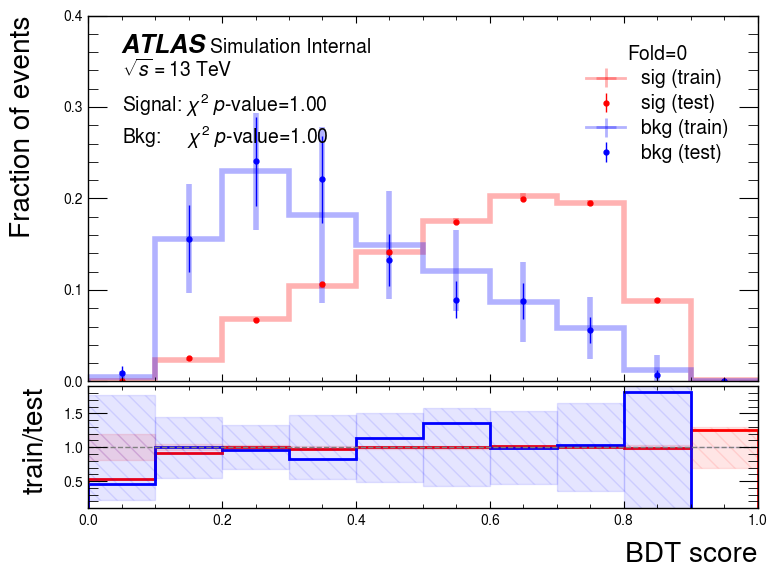

In [41]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 0
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_10bins_{fold}_Model8_3ClassPerProcess.png')